# Community Detection in Multiplex Networks

In this chapter we will:

1. Learn what a **multiplex network** is: the same people, connected by several kinds of ties.
2. Compare **three ways** to find communities when there are several layers: flattening, layer by layer, and analyzing all layers at once.
3. Try them on a toy example and on a real five-layer social network.
__________

### The problem

 **This chapter asks: how do we find communities when there are several layers, and how do different methods affect the communities we identify?**

### Table of contents

**1. Why multiplex networks matter** 

- Recap: single-layer community detection:
  - We have learned the community detection approaches for simple static networks, where all edges are supposed to be of the same type

- However, real networks are often more complicated:
  - Most social survey data have several layers (work, lunch, friendship…)

- Layers can also represent a network at different points in time.

- This chapter focuses on multiple relationship type.

*References:* [Newman & Girvan (2004)](https://doi.org/10.1103/PhysRevE.69.026113); [Kivelä et al. (2014)](https://doi.org/10.1093/comnet/cnu016); [Dickison et al. (2016)](https://doi.org/10.1017/CBO9781139941907).


**2. What is a multiplex network?**

- Definition and scope
  - The basic idea is to represent each relationship type as a separate layer.
  - The same person can appear in several layers.

- A toy example:
  - 12 colleagues and 3 layers (work, leisure, lunch)
  - Show the graph
  - Use this example throughout the chapter

*References:* [Kivelä et al. (2014)](https://doi.org/10.1093/comnet/cnu016); [Dickison et al. (2016)](https://doi.org/10.1017/CBO9781139941907).


**3. What community membership means across layers?**

- Pillar communities: 

  - Each actor belongs to the same community in every layer.

- Semi-pillar and non-pillar structure: 

  - An actor’s community assignment can differ between layers
  — for example, belonging to one group at work and another at lunch.

- Why distinguish these structures?
  - Some methods give each person one shared assignment, while others allow separate assignments across layers.

*References:* [Magnani et al. (2021)](https://doi.org/10.1145/3444688).


**4. Way 1: Flattening**
- How it works: 
(Simpliy) Merge all layers into one ordinary network, run a single-layer community detection algorithm on it (such as Louvain from Class 07), then copy each actor's community back to all of that actor's nodes.

- *Code* Apply the method to the toy example in Python

- Weaknesses
  - Flattening loses layer-specific information and cannot represent different community memberships for the same actor across layers

*References:* [Berlingerio et al. (2011)](https://doi.org/10.1109/ASONAM.2011.104); [Blondel et al. (2008)](https://doi.org/10.1088/1742-5468/2008/10/P10008); [Magnani et al. (2021)](https://doi.org/10.1145/3444688).



**5. Way 2: Layer by layer**
- How it works: 
  - First find communities in each layer separately (usually with a single-layer algorithm), then use that information to cluster the actors into one final answer 

**Three approaches**
- Pattern mining(ABACUS): 
  - find objects that frequently co-occur together in different transactions. 
- Consensus(EMCD): 
  - treat the per-layer results as an ensemble of solutions and find one representative solution that best summarizes them, by optimizing an objective function 
- PMM: 
  - extract structural features from each layer, put them side by side, use PCA to keep the main patterns, then run k-means to assign communities
  - need number of communities given in advance

- *code* one simple consensus approach

- Strengths and weaknesses

*References:* [Magnani et al. (2021)](https://doi.org/10.1145/3444688); [Berlingerio et al. (2013)](https://doi.org/10.1007/s10618-013-0331-0); [Tagarelli et al. (2017)](https://doi.org/10.1007/s10618-017-0528-8); [Tang et al. (2009)](https://doi.org/10.1109/ICDM.2009.20); [Tang et al. (2012)](https://doi.org/10.1007/s10618-011-0231-0).


**6. Way 3: Direct multilayer methods**
-How it words:
  - Direct multilayer methods detect communities by **jointly analyzing the network layers while preserving their distinct relationships**. Within this framework, two approaches are multilayer modularity optimization and layered stochastic block modeling.

*Multilayer modularity optimization*

- Each person has a copy in each layer. 
  - The method looks for strong community structure within layers, while encouraging the same person’s copies to stay together.

- The coupling parameter ω (omega) 
  - It controls how strongly community memberships are encouraged to stay similar across layers. 
    - This allows, for example, someone to belong to different groups in the work and friendship layers when the layer-specific relationships support that distinction (Mucha et al., 2010).
  - ω = 0
    -  The layers are analyzed independently.
  - very large ω:
    - The same groups in every layer (like Way 1)

- *code* (Show how the results change when omega is low or high)

- Strengths and weakness

*Extended:Layered stochastic block models (SBMs)*

- Recap: ordinary SBM. 
  - A stochastic block model groups nodes and models the connections within and between those groups. Groups do not have to be internally dense.
  - It observes the network and work backward: which grouping, together with which connection patterns, could plausibly explain the observed relationships?

- Extension to multiple layers. A layered SBM analyzes different relationship types—such as work, friendship, and lunch—while allowing each layer to have its own connection patterns.
  - Shared grouping. In the shared-membership version, each person belongs to the same group across all layers. The relationships between groups can differ by layer.
  - Joint inference. The model uses all layers together to infer both the shared grouping and the layer-specific connection patterns.
  - Model selection. A description-length approach balances how well the model explains the data against its complexity, helping avoid unnecessary groups and parameters.

- Final output. 
  - One shared partition of the nodes, together with a description of how those groups connect in each layer.

*References:* [Magnani et al. (2021)](https://doi.org/10.1145/3444688); [Mucha et al. (2010)](https://doi.org/10.1126/science.1184819); [Traag et al. (2019)](https://doi.org/10.1038/s41598-019-41695-z); [Peixoto (2015)](https://doi.org/10.1103/PhysRevE.92.042807).



**8. Real example: AUCS**
- Introduce the data: 
  - 61 participating university employees and five layers — work, lunch, leisure, co-authorship, and Facebook.
- Describe the layers: 
  - Produce one summary table and a figure with a panel for each layer.
- Apply and compare: 
  - Reuse the three methods developed on the toy example; compare who gets grouped together under each method.
- Interpret: 
  - Use the original relationships to explain what similar or different groupings reveal about employees’ social connections.

Purpose: This is a short application of the methods, rather than a second explanation of each algorithm. I will explore differences without assuming that one method must be the winner.

*References:* [Rossi & Magnani (2015)](https://doi.org/10.1016/j.chaos.2014.12.022).


**9. Limitations**
- Explain how method assumptions influence the communities found
- How the layers we include affect the results
- Challenge in treating special networks
  - sparse and directed networks

*References:* [Magnani et al. (2021)](https://doi.org/10.1145/3444688); [Kivelä et al. (2014)](https://doi.org/10.1093/comnet/cnu016); [Mucha et al. (2010)](https://doi.org/10.1126/science.1184819).


__________

In [19]:
# import your packages! and whatever else that's basic that you need
# Sections 5 and 7 need packages outside cmns-core:
#   - leidenalg + igraph : use the cmns-igraph kernel
#   - graph-tool         : use the cmns-graphtool kernel
#   - uunet (optional, Python port of the R multinet library): pip install uunet
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')
rc('axes', axisbelow=True)

## 1. Warm-up: One Network or Many?

### 1.1 The toy example
Imagine 12 colleagues with three kinds of ties:
- **work:** two teams, people 0–5 and people 6–11;
- **leisure:** the same two teams;
- **lunch:** a *different* split, by office floor: {0, 1, 2, 6, 7, 8} and {3, 4, 5, 9, 10, 11}.

Let's find communities two ways: in each layer separately, and in the flattened network (all layers added together).

In [20]:
def planted_layer(groups, p_in, p_out, seed):
    """
    Build one layer with planted groups: dense ties inside groups, sparse ties between them.

    Parameters
    ----------
    groups : list of lists
        The planted groups, e.g. [[0, 1, 2], [3, 4, 5]].
    p_in : float
        Probability of a tie between two members of the same group.
    p_out : float
        Probability of a tie between members of different groups.
    seed : int
        Random seed, so the layer is the same every time.

    Returns
    -------
    G : networkx.Graph
        One layer of the multiplex network, containing every actor.
    """
    rng = np.random.default_rng(seed)
    group_of = {a: g for g, members in enumerate(groups) for a in members}
    actors = sorted(group_of)
    G = nx.Graph()
    G.add_nodes_from(actors)                       # every actor appears in every layer
    for i in actors:
        for j in actors:
            if i < j:                              # visit each pair once
                p = p_in if group_of[i] == group_of[j] else p_out
                if rng.random() < p:
                    G.add_edge(i, j)
    return G


def flatten(layers):
    """
    Flatten a multiplex network into one weighted network.

    Parameters
    ----------
    layers : dict
        {layer name: networkx.Graph}; all layers share the same actors.

    Returns
    -------
    F : networkx.Graph
        One network in which the weight of tie (i, j) is the number of layers that contain it.

    Citations
    ---------
    Berlingerio, Coscia & Giannotti (2011); Magnani et al. (2021), Section 4.1.
    """
    F = nx.Graph()
    for G in layers.values():
        F.add_nodes_from(G.nodes())
        for i, j in G.edges():
            w = F[i][j]['weight'] + 1 if F.has_edge(i, j) else 1
            F.add_edge(i, j, weight=w)
    return F


teams  = [[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11]]
floors = [[0, 1, 2, 6, 7, 8], [3, 4, 5, 9, 10, 11]]
multiplex = {
    'work':    planted_layer(teams,  p_in=0.8, p_out=0.05, seed=1),
    'leisure': planted_layer(teams,  p_in=0.6, p_out=0.10, seed=2),
    'lunch':   planted_layer(floors, p_in=0.8, p_out=0.05, seed=3),
}
for name, G in multiplex.items():
    print(f"{name:8s}: {G.number_of_nodes()} actors, {G.number_of_edges()} ties")

work    : 12 actors, 24 ties
leisure : 12 actors, 19 ties
lunch   : 12 actors, 27 ties


In [5]:
def co_membership_similarity(part_a, part_b):
    """
    Share of actor pairs on which two partitions agree (both "together" or both "apart").

    Parameters
    ----------
    part_a, part_b : dict
        {actor: community label}, over the same actors.

    Returns
    -------
    float
        1.0 means the partitions are identical up to relabeling.
        (This is the Rand index; NMI will be introduced in Section 8.)
    """
    actors = sorted(part_a)
    agree, total = 0, 0
    for x in range(len(actors)):
        for y in range(x + 1, len(actors)):
            i, j = actors[x], actors[y]
            agree += (part_a[i] == part_a[j]) == (part_b[i] == part_b[j])
            total += 1
    return agree / total


def to_labels(communities):
    """Convert a list of sets into {actor: community label}."""
    return {a: c for c, members in enumerate(communities) for a in members}


# Layer-by-layer: run Louvain on each layer separately
partitions = {name: to_labels(nx.community.louvain_communities(G, seed=0))
              for name, G in multiplex.items()}

# Flattening: add the layers together, then run Louvain once
F = flatten(multiplex)
partitions['flattened'] = to_labels(nx.community.louvain_communities(F, weight='weight', seed=0))

truth = {'teams': to_labels([set(g) for g in teams]), 'floors': to_labels([set(g) for g in floors])}
print(f"{'partition':10s} {'similarity to teams':>20s} {'similarity to floors':>21s}")
for name, part in partitions.items():
    print(f"{name:10s} {co_membership_similarity(part, truth['teams']):20.2f} "
          f"{co_membership_similarity(part, truth['floors']):21.2f}")

partition   similarity to teams  similarity to floors
work                       1.00                  0.45
leisure                    0.83                  0.47
lunch                      0.45                  1.00
flattened                  1.00                  0.45


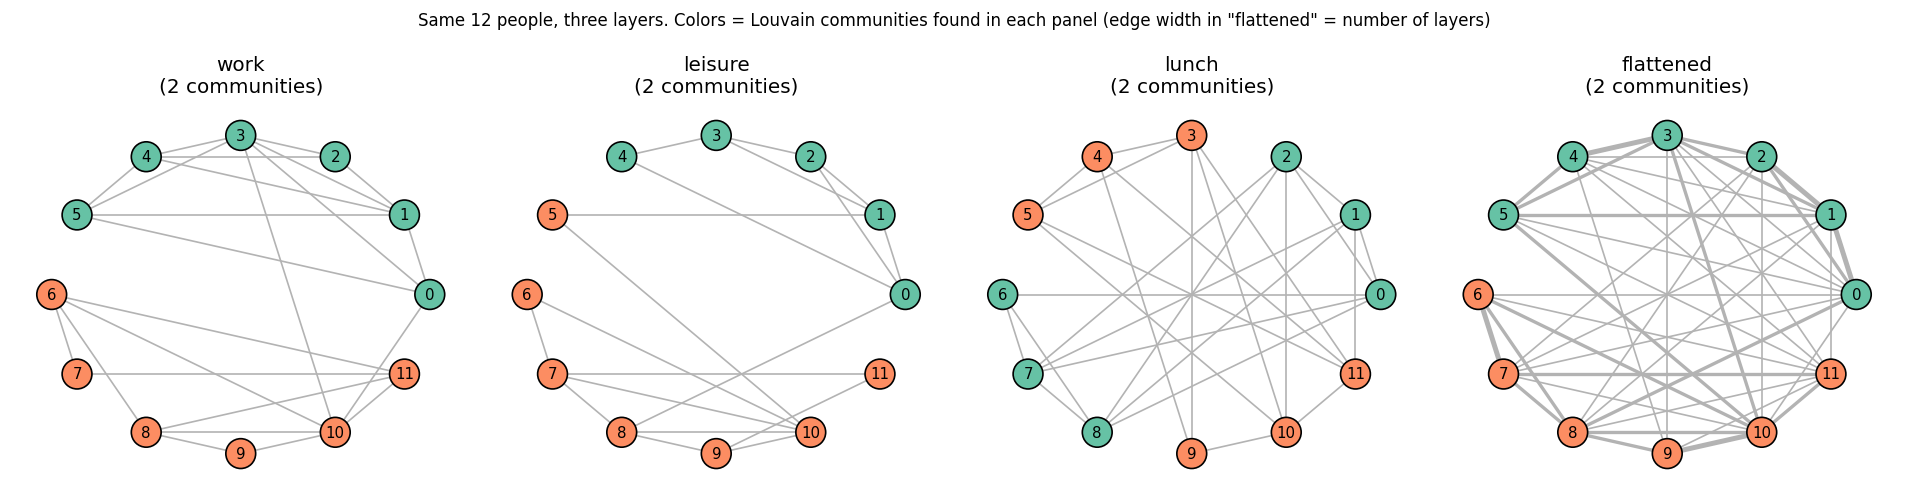

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), dpi=120)
pos = nx.circular_layout(range(12))
panels = [('work', multiplex['work']), ('leisure', multiplex['leisure']),
          ('lunch', multiplex['lunch']), ('flattened', F)]

for ax, (name, G) in zip(axes, panels):
    part = partitions[name]
    widths = [G[i][j].get('weight', 1) for i, j in G.edges()]
    nx.draw_networkx_edges(G, pos, width=widths, edge_color='.7', ax=ax)
    nx.draw_networkx_nodes(G, pos, node_color=[plt.cm.Set2(part[n] % 8) for n in G.nodes()],
                           node_size=320, edgecolors='k', ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
    ax.set_title(f"{name}\n({len(set(part.values()))} communities)", fontsize='large')
    ax.axis('off')

fig.suptitle('Same 12 people, three layers. Colors = Louvain communities found in each panel '
             '(edge width in "flattened" = number of layers)', fontsize='medium')
plt.tight_layout()
plt.show()

_______

## References and further resources

1. Berlingerio, M., Coscia, M., & Giannotti, F. (2011). Finding and characterizing communities in multidimensional networks. In *2011 International Conference on Advances in Social Networks Analysis and Mining (ASONAM)* (pp. 490–494). IEEE. https://doi.org/10.1109/ASONAM.2011.104
2. Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008. https://doi.org/10.1088/1742-5468/2008/10/P10008
3. Dickison, M. E., Magnani, M., & Rossi, L. (2016). *Multilayer social networks*. Cambridge University Press. https://doi.org/10.1017/CBO9781139941907
4. Kivelä, M., Arenas, A., Barthelemy, M., Gleeson, J. P., Moreno, Y., & Porter, M. A. (2014). Multilayer networks. *Journal of Complex Networks*, 2(3), 203–271. https://doi.org/10.1093/comnet/cnu016
5. Magnani, M., Hanteer, O., Interdonato, R., Rossi, L., & Tagarelli, A. (2021). Community detection in multiplex networks. *ACM Computing Surveys*, 54(3), Article 48, 1–35. https://doi.org/10.1145/3444688
6. Mucha, P. J., Richardson, T., Macon, K., Porter, M. A., & Onnela, J.-P. (2010). Community structure in time-dependent, multiscale, and multiplex networks. *Science*, 328(5980), 876–878. https://doi.org/10.1126/science.1184819
7. Newman, M. E. J., & Girvan, M. (2004). Finding and evaluating community structure in networks. *Physical Review E*, 69(2), 026113. https://doi.org/10.1103/PhysRevE.69.026113
8. Peixoto, T. P. (2015). Inferring the mesoscale structure of layered, edge-valued, and time-varying networks. *Physical Review E*, 92(4), 042807. https://doi.org/10.1103/PhysRevE.92.042807
9. Rossi, L., & Magnani, M. (2015). Towards effective visual analytics on multiplex and multilayer networks. *Chaos, Solitons & Fractals*, 72, 68–76. https://doi.org/10.1016/j.chaos.2014.12.022
10. Traag, V. A., Waltman, L., & van Eck, N. J. (2019). From Louvain to Leiden: Guaranteeing well-connected communities. *Scientific Reports*, 9, 5233. https://doi.org/10.1038/s41598-019-41695-z
11. Alhajj, R., & Rokne, J. (Eds.). (2014). *Encyclopedia of social network analysis and mining*. Springer. https://doi.org/10.1007/978-1-4614-6170-8
12. Kuncheva, Z., & Montana, G. (2015). Community detection in multiplex networks using locally adaptive random walks. In *Proceedings of the 2015 IEEE/ACM International Conference on Advances in Social Networks Analysis and Mining 2015* (pp. 1308–1315). ACM. https://doi.org/10.1145/2808797.2808852

13. Berlingerio, M., Pinelli, F., & Calabrese, F. (2013). ABACUS: frequent pAttern mining-BAsed Community discovery in mUltidimensional networkS. *Data Mining and Knowledge Discovery*, 27, 294–320. https://doi.org/10.1007/s10618-013-0331-0
14. Tagarelli, A., Amelio, A., & Gullo, F. (2017). Ensemble-based community detection in multilayer networks. *Data Mining and Knowledge Discovery*, 31(5), 1506–1543. https://doi.org/10.1007/s10618-017-0528-8
15. Tang, L., Wang, X., & Liu, H. (2009). Uncovering groups via heterogeneous interaction analysis. In *2009 Ninth IEEE International Conference on Data Mining* (pp. 503–512). IEEE. https://doi.org/10.1109/ICDM.2009.20
16. Tang, L., Wang, X., & Liu, H. (2012). Community detection via heterogeneous interaction analysis. *Data Mining and Knowledge Discovery*, 25(1), 1–33. https://doi.org/10.1007/s10618-011-0231-0

**Software:** `leidenalg` multiplex guide, https://leidenalg.readthedocs.io/en/latest/multiplex.html; `multinet` R package (includes the AUCS data), https://cran.r-project.org/package=multinet; `graph-tool` inference guide, https://graph-tool.skewed.de/static/docs/stable/demos/inference/inference.html